# 1 Dataset Introduction

Financial markets are closely linked: the price of one asset is often affected by movements in stock markets, other commodities, currencies and the wider economy. Gold is a common example. Investors often treat it as a "safe haven" and buy it when stock markets fall or inflation rises, and because it is priced in US dollars it also responds to changes in the dollar's value and in interest rates.

This dataset brings these factors together in one daily record, covering two major US stock indices (the S&P 500 and NASDAQ), five commodities (gold, silver, oil, platinum and palladium), two exchange rates and three US economic indicators. This makes it suitable for studying how the assets relate to one another and for building models that predict a future price, such as gold, from the behaviour of the rest of the market.

## 1.1 Dataset Identification

The dataset was retrieved from Kaggle, where it was published by the user franciscogcc under the title "Gold Price Regression". It is a daily time series of financial information for market indices, commodities, economic indicators and foreign exchange rates. The market indices and commodities are represented by the price of the exchange-traded fund (ETF) that tracks each one, rather than by the index or spot price itself. Kaggle does not verify uploaded datasets, so this source should be treated with more caution than a curated repository such as UC Irvine. The dataset can be found at the following URL: 

https://www.kaggle.com/datasets/franciscogcc/financial-data

The dataset contains forty-seven (47) attributes over 3,904 rows, covering trading days from 14 January 2010 to 23 October 2024. The file does not define a target. As the dataset was published for regression on the gold price, gold close is treated as the target, with the remaining forty-six (46) attributes as features. The attributes are defined as the following types:

- <mark>Date</mark>: date Presented as a string in the format YYYY-MM-DD. For example: 2010-01-14.

- <mark>Numerical (Continuous)</mark>: the open, high, low and close prices of sp500, nasdaq, silver, oil, platinum, palladium and gold; the daily range (high-low) of each asset except gold; the exchange rates usd_chf and eur_usd; and the macroeconomic indicators us_rates_%, CPI and GDP (39 attributes in total). Prices and rates can take any real value and have no defined upper limit.

- <mark>Numerical (Discrete)</mark>: sp500 volume, nasdaq volume, silver volume, oil volume, platinum volume, palladium volume, gold volume. Volumes are counts of units traded, so they only take whole-number values, although the file stores them as decimals.

There are no categorical attributes. Around 5% of rows are empty apart from the date; these appear to be non-trading days. us_rates_%, CPI and GDP are published monthly or quarterly, so they are present on only around 5%, 5% and 1% of rows respectively. They would need to be forward-filled or removed before modelling. Table 1 summarises the attributes.

| Attribute(s) | Data type | Variable type | Description |
|---|---|---|---|
| date | String | Date | Trading day (YYYY-MM-DD) |
| [asset] open / high / low / close | Float | Numerical (continuous) | ETF price at open, highest, lowest and at close of the day |
| [asset] high-low | Float | Numerical (continuous) | Daily price range (high minus low) |
| [asset] volume | Float | Numerical (discrete) | Number of units traded that day |
| usd_chf, eur_usd | Float | Numerical (continuous) | Exchange rates |
| us_rates_% | Float | Numerical (continuous) | US interest rate (%) |
| CPI, GDP | Float | Numerical (continuous) | US Consumer Price Index and Gross Domestic Product |
| gold close | Float | Numerical (continuous) | Target: gold ETF closing price |

## 1.2. Supervised Learning Task Identification

**Financial Regression**

Herein, the objective of the supervised learning task is to use regression techniques to accurately predict the closing price of gold (gold close). This can also be determined from the following:

- The target variable, gold close, is numerical (continuous), meaning it can take any value within a range rather than belonging to a fixed set of categories.
- The dataset contains no categorical attributes that could act as a class label; all attributes other than date are numerical.
- The data is an ordered daily time series, so the task is to estimate a future value from earlier values of gold and the other assets, rates and indicators.

A classification task can also be performed by deriving a categorical target from the data, such as whether the price of gold rises or falls on the following day. However, this is not the dataset's primary purpose.

# 2. Exploratory Data Analysis

With the identification of the dataset, and the supervised learning task being defined as Financial Regression and regression respectively, exploratory data analysis (EDA) can be undertaken to facilitate a deeper understanding of the structure of the data, as well as allowing for identification of issues with data quality (IBM, 2024). This is particularly important for this dataset, as it contains missing values on non-trading days and macroeconomic indicators (us_rates_%, CPI and GDP) that are only recorded monthly or quarterly. Furthermore, by creating visualisations of the dataset, it is easier to identify any patterns, trends, or correlations that are present between gold and the other assets, rates and indicators. With conclusions drawn from this exploration, suitable machine learning algorithms and models can be identified, and features can be engineered to improve the performance of the chosen model(s). These model(s) can then be evaluated for their efficacy when provided data of a similar format to the original dataset.

Within the following section, questions and assumptions about the dataset will be proposed. Then an explanation of how data will be split into training, validation, and testing sets will be provided; as the data is a time series, this split will be made chronologically rather than at random, so that the model is never trained on data from after the period it is tested on. This will be followed by EDA, defining the process and results, which will then be measured against the previously proposed questions and assumptions.

### 2.1 Question(s) identification

Research questions should allow the researcher or investigator to set out what they want to know as a hypothesis, regardless of whether the result support the hypothesis or not (Mayo et al., 2013). By providing well posed questions and assumptions the EDA process will be able to support or reject their claims (Lane, 2018). Table 2 below provides several questions related to the dataset and their associated assumptions.

| ID | Question | Assumption |
|---|---|---|
| RQ1 | Does the price of gold move with the stock market (sp500 and nasdaq)? | Gold is often bought as a "safe haven" when stock markets fall, so it is expected that daily changes in gold will show little or a slightly negative relationship with daily changes in the stock indices. Over the full period, however, both may show a positive relationship simply because both rose over time. |
| RQ2 | Do other precious metals (silver, platinum and palladium) move with gold? | It is expected that silver will show a strong positive correlation with gold, as both are traded as precious metals and stores of value. Platinum and palladium are expected to show a weaker relationship, as their prices depend more on industrial demand such as vehicle manufacturing. |
| RQ3 | Do interest rates (us_rates_%) impact the price of gold? | Gold pays no interest, so it is expected that higher interest rates will make it less attractive than interest-bearing assets, resulting in a negative relationship between interest rates and the price of gold. |
| RQ4 | Does the strength of the US dollar (eur_usd and usd_chf) impact the price of gold? | As gold is priced in US dollars, it is expected that a weaker dollar will coincide with a higher gold price. This would appear as a positive relationship with eur_usd and a negative relationship with usd_chf. |
| RQ5 | Does inflation (CPI) impact the price of gold? | Gold is commonly treated as a protection against inflation, so it is expected that periods of rising CPI will coincide with a rising gold price. As CPI is only recorded monthly, this relationship is expected to be visible over long periods rather than day to day. |
| RQ6 | Does the previous day's price of gold predict the next day's price? | It is expected that the previous day's closing price will be the strongest single predictor of the next day's price, as daily price changes are usually small relative to the price itself. |

2.2 Splitting the dataset
The dataset will be split into three groups; the training set, the validation set, and the testinG set. It is important to train the model on a distinct set of data to the testing data, otherwise the model may memorise the training data and overfit to it, making it unreliable in real-world scenarios where it is expected to perform on unseen data. (Apicella et al., 2024). This is also referred to as data-leakage, which refers to the unintentional provision of data from outside the training dataset during model training.

To split the data, the module train_test_split from Scikit learn is used to allocate two subsets of data. This initial split creates a training and testing dataset, the code for which is shown in Figure 2; to allow for accurate replication of this split, the random_state parameter is used. This parameter is used to control the random number generator for the random state. In this case, the number 42 has been used, and this value can be used again to perform the same split (Scikit Learn, 2024.)

In [14]:
import pandas as pd
import random as rand
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import mglearn
from scipy.stats import randint, uniform

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import (train_test_split, KFold, learning_curve,
                                     validation_curve, GridSearchCV, RandomizedSearchCV,
                                     cross_val_score)

from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor

from sklearn.metrics import (r2_score, mean_absolute_error, mean_squared_error,
                             accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_curve, roc_auc_score)

In [2]:
DATA_PATH = "../datasets/"
price = pd.read_csv(DATA_PATH + "financial_regression.csv", parse_dates=["date"])
price = price.sort_values("date")

In [3]:
# Remove non-trading days (rows with no market data)
price = price.dropna(subset=["sp500 close"]).reset_index(drop=True)

# Fill gaps in slow-moving columns with the last known value
fill_cols = ["us_rates_%", "CPI", "GDP", "usd_chf", "eur_usd"]
price[fill_cols] = price[fill_cols].ffill()

# Target: next trading day's gold close
price["target"] = price["gold close"].shift(-1)
price = price.dropna().reset_index(drop=True)

In [4]:
X = price.drop(columns=["date", "target"])
y = price["target"]

In [5]:
# Split off 70% training data & 30% temporary data
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30)

# Split the temporary data in half: 20% validation, 20% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50)

print(len(X_train), len(X_val), len(X_test))

2565 550 550


In [6]:
price.info()

<class 'pandas.DataFrame'>
RangeIndex: 3665 entries, 0 to 3664
Data columns (total 48 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   date                3665 non-null   datetime64[us]
 1   sp500 open          3665 non-null   float64       
 2   sp500 high          3665 non-null   float64       
 3   sp500 low           3665 non-null   float64       
 4   sp500 close         3665 non-null   float64       
 5   sp500 volume        3665 non-null   float64       
 6   sp500 high-low      3665 non-null   float64       
 7   nasdaq open         3665 non-null   float64       
 8   nasdaq high         3665 non-null   float64       
 9   nasdaq low          3665 non-null   float64       
 10  nasdaq close        3665 non-null   float64       
 11  nasdaq volume       3665 non-null   float64       
 12  nasdaq high-low     3665 non-null   float64       
 13  us_rates_%          3665 non-null   float64       
 14  CPI

In [9]:
price.head(10)

,date,sp500 open,sp500 high,sp500 low,sp500 close,sp500 volume,sp500 high-low,nasdaq open,nasdaq high,nasdaq low,...,palladium low,palladium close,palladium volume,palladium high-low,gold open,gold high,gold low,gold close,gold volume,target
0,2010-04-01,117.80,118.25,117.10,117.80,161083608.0,1.15,48.34,48.70,47.790,...,48.7730,48.92,135299.0,0.5470,109.97,110.4700,109.92,110.26,11370417.0,110.89
1,2010-04-05,118.25,118.84,117.92,118.76,105621743.0,0.92,48.26,48.72,48.140,...,49.1100,50.38,191249.0,1.8700,110.56,110.9837,110.27,110.89,8207564.0,111.03
2,2010-04-06,118.42,119.25,118.29,119.04,110194919.0,0.96,48.49,48.90,48.390,...,50.3101,50.81,226947.0,0.7899,110.89,111.5100,110.83,111.03,10321993.0,112.49
3,2010-04-07,118.80,119.36,117.81,118.36,184432309.0,1.55,48.69,48.87,48.370,...,50.5101,50.89,483783.0,0.7199,111.85,112.9300,111.77,112.49,19127617.0,112.65
4,2010-04-08,117.95,118.97,117.60,118.77,158495871.0,1.37,48.51,48.82,48.240,...,50.0800,50.56,382541.0,0.5500,112.47,112.9800,112.13,112.65,12444414.0,113.64
5,2010-04-09,119.02,119.60,118.80,119.55,132701705.0,0.80,48.77,49.05,48.635,...,50.8000,51.32,192829.0,0.5800,113.09,114.0700,112.74,113.64,16427638.0,113.01
6,2010-04-12,119.70,120.05,119.56,119.74,110200946.0,0.49,49.05,49.20,48.940,...,51.5600,51.94,172620.0,0.9000,113.64,114.1300,112.98,113.01,11118097.0,112.69
7,2010-04-13,119.62,120.04,119.00,119.83,121901060.0,1.04,49.02,49.35,48.860,...,51.4000,52.92,365120.0,1.5500,113.12,113.1600,112.06,112.69,10983964.0,113.03
8,2010-04-14,120.27,121.19,120.08,121.19,161608989.0,1.11,49.57,49.92,49.500,...,54.1600,54.74,373814.0,0.8400,113.23,113.6600,112.78,113.03,10573838.0,113.65
9,2010-04-15,120.99,121.57,120.95,121.29,144514805.0,0.62,49.88,50.19,49.870,...,54.2600,54.48,220926.0,0.6600,112.90,113.7100,112.85,113.65,10952007.0,111.24


In [10]:
price.describe()

,date,sp500 open,sp500 high,sp500 low,sp500 close,sp500 volume,sp500 high-low,nasdaq open,nasdaq high,nasdaq low,...,palladium low,palladium close,palladium volume,palladium high-low,gold open,gold high,gold low,gold close,gold volume,target
count,3665,3665.000000,3665.000000,3665.000000,3665.000000,3.665000e+03,3665.000000,3665.000000,3665.000000,3665.000000,...,3665.000000,3665.000000,3.665000e+03,3665.000000,3665.000000,3665.000000,3665.000000,3665.000000,3.665000e+03,3665.000000
mean,2017-07-11 07:30:16.207367,270.909766,272.368548,269.323742,270.957577,1.111154e+08,3.044806,183.273650,184.583556,181.847858,...,108.860939,110.004465,6.963059e+04,2.269763,145.960863,146.607884,145.268687,145.961002,9.555628e+06,145.999368
min,2010-04-01 00:00:00,103.110000,103.420000,101.130000,102.200000,2.027001e+07,0.300000,42.670000,42.821500,41.550000,...,40.700000,41.860000,3.157000e+03,0.230000,100.920000,100.990000,100.232600,100.500000,1.436508e+06,100.500000
25%,2013-11-19 00:00:00,177.500000,178.430000,176.880000,177.480000,6.666580e+07,1.290000,83.250000,83.860000,82.980000,...,69.021000,69.520000,2.068000e+04,0.870000,120.910000,121.400000,120.470000,120.900000,5.767703e+06,120.910000
50%,2017-07-12 00:00:00,243.340000,244.350000,242.380000,243.360000,9.168476e+07,2.110000,141.800000,142.690000,141.060000,...,83.720000,84.270000,3.777900e+04,1.425300,138.440000,139.150000,137.800000,138.560000,8.002766e+06,138.620000
75%,2021-03-03 00:00:00,376.640000,380.060000,372.900000,377.250000,1.350407e+08,3.850000,286.100000,289.483800,283.190000,...,142.520000,144.260000,8.156100e+04,2.713400,168.020000,168.750000,167.225000,168.030000,1.141523e+07,168.080000
max,2024-10-22 00:00:00,585.910000,586.120000,582.580000,584.590000,7.095045e+08,22.960000,503.070000,503.520000,498.390000,...,277.000100,295.000000,1.199042e+06,45.392300,253.060000,253.940000,252.520000,253.930000,9.369811e+07,253.930000
std,NaN,120.678926,121.327919,119.972208,120.700019,6.800137e+07,2.667298,122.158182,123.082771,121.129117,...,56.767141,57.582458,9.548331e+04,2.557692,29.428594,29.582321,29.244027,29.437228,6.127341e+06,29.482280


In [13]:
unique_values = price["sp500 high"].unique()
print(unique_values)

[118.25 118.84 119.25 ... 585.39 584.85 584.5 ]


## Univariate Analysis

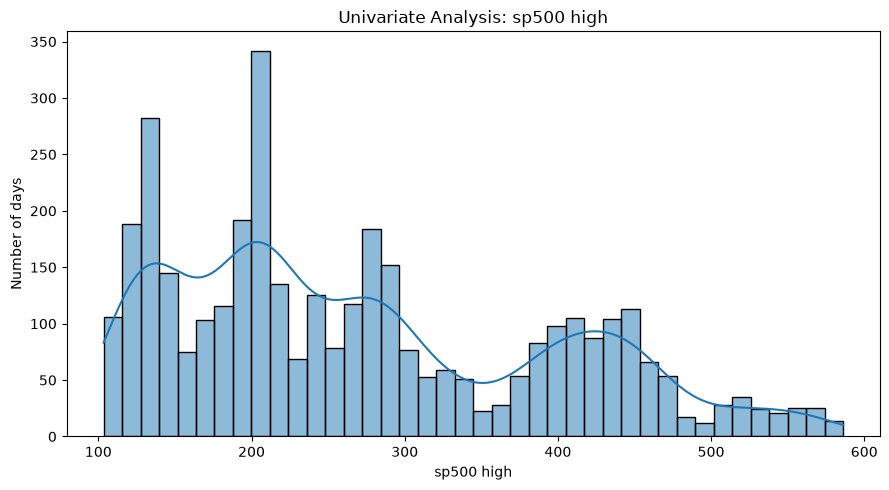

In [30]:
col = "sp500 high"

fig, ax = plt.subplots(figsize=(9, 5))

sns.histplot(price[col], bins=40, kde=True, ax=ax)
ax.set_title(f"Univariate Analysis: {col}")
ax.set_xlabel(col)
ax.set_ylabel("Number of days")

plt.tight_layout()
plt.show()

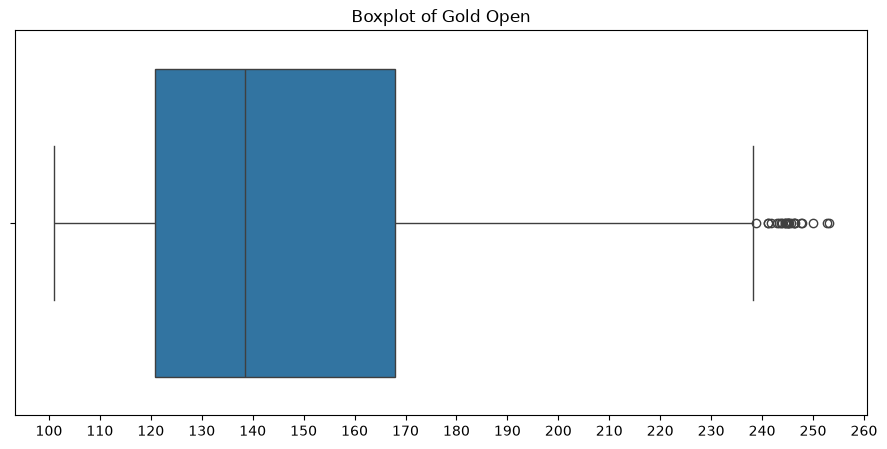

In [37]:

# Boxplot: median, spread and outliers
plt.figure(figsize=(11, 5))

sns.boxplot(x = price["gold open"])
plt.title("Boxplot of Gold Open")
plt.xlabel("")

min_gold_open = np.floor(price["gold open"].min() / 10) * 10
max_gold_open = np.ceil(price["gold open"].max() / 10) * 10

plt.xticks(np.arange(min_gold_open, max_gold_open + 1, 10))

plt.show()

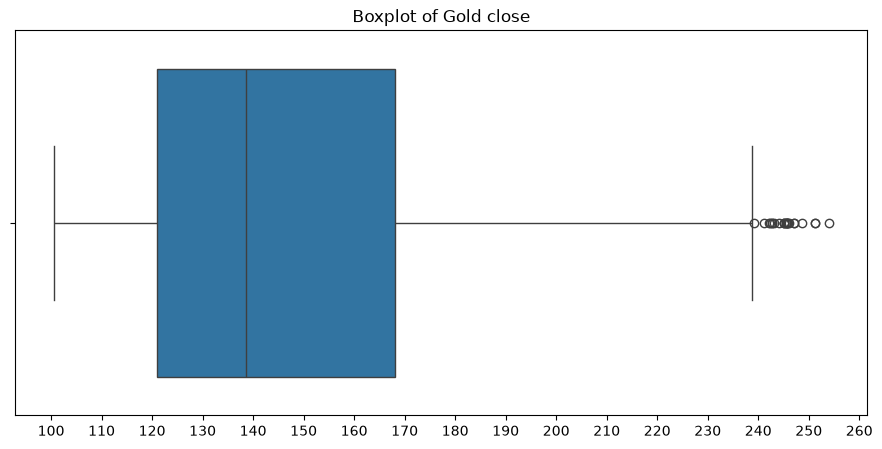

In [38]:

# Boxplot: median, spread and outliers
plt.figure(figsize=(11, 5))

sns.boxplot(x = price["gold close"])
plt.title("Boxplot of Gold close")
plt.xlabel("")

min_gold_close = np.floor(price["gold close"].min() / 10) * 10
max_gold_close = np.ceil(price["gold close"].max() / 10) * 10

plt.xticks(np.arange(min_gold_close, max_gold_close + 1, 10))

plt.show()

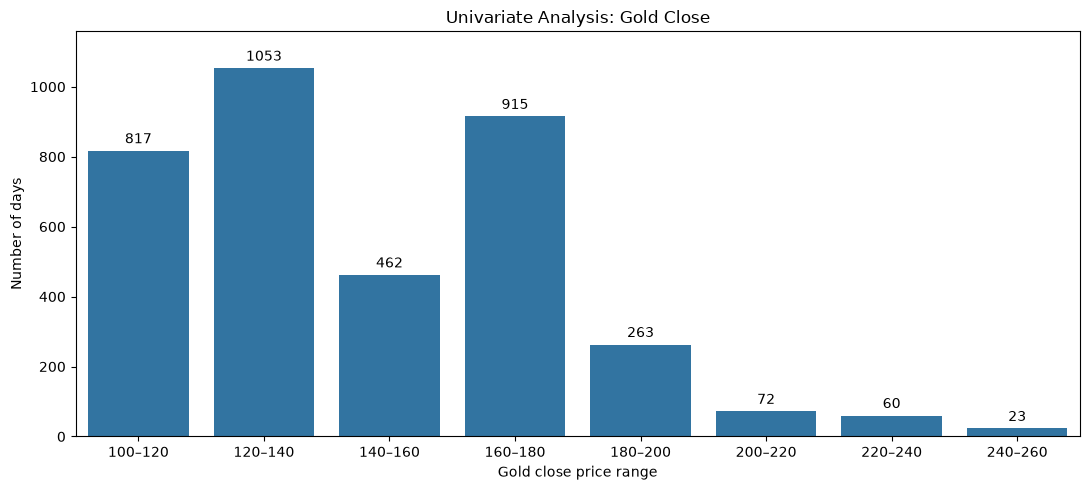

In [44]:
col = "gold close"

# Group prices into ranges of 20 (100–120, 120–140, ...)
bins = np.arange(100, 261, 20)
labels = [f"{b}–{b + 20}" for b in bins[:-1]]
gold_close_range = pd.cut(price[col], bins=bins, labels=labels, right=False)

plt.figure(figsize=(11, 5))
gold_close_plot = sns.countplot(x=gold_close_range)

gold_close_plot.bar_label(gold_close_plot.containers[0], padding=3)

gold_close_plot.set_title("Univariate Analysis: Gold Close")
gold_close_plot.set_xlabel("Gold close price range")
gold_close_plot.set_ylabel("Number of days")
gold_close_plot.margins(y=0.1)

plt.tight_layout()
plt.show()

## Bivariate Analysis

